In [2]:
from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()


df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target


df['species_name'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})


print("Here is what our dataset looks like:")
display(df.head())

Here is what our dataset looks like:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
from sklearn.model_selection import train_test_split


print("Checking for missing values:")
print(df.isnull().sum())
print("-" * 30)


X = iris.data  # The 4 physical measurements
y = iris.target  # The species labels (0, 1, 2)

# 3. Split into Training (80%) and Testing (20%) sets
# random_state=42 ensures our split is reproducible every time we run it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data preparation complete successfully!")
print(f"Total samples: {len(X)}")
print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Checking for missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species_name         0
dtype: int64
------------------------------
Data preparation complete successfully!
Total samples: 150
Training set size: 120 samples
Testing set size: 30 samples


Decision Tree Accuracy: 100.00%
KNN Model Accuracy: 100.00%
----------------------------------------


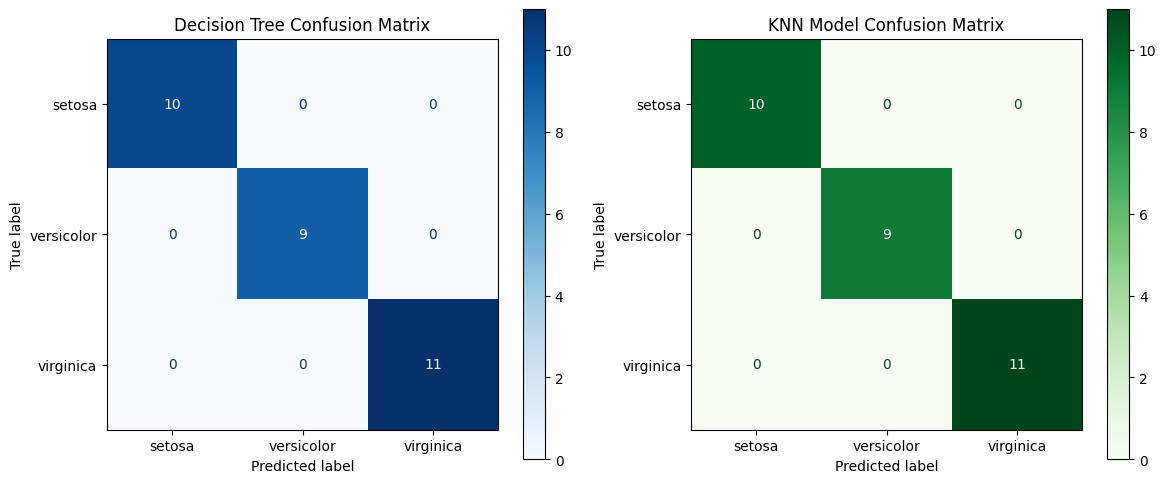

In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Make predictions on our test set (the 30 hidden samples)
dt_predictions = decision_tree.predict(X_test)
knn_predictions = knn_model.predict(X_test)

# 2. Calculate Accuracy Scores
dt_accuracy = accuracy_score(y_test, dt_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")
print(f"KNN Model Accuracy: {knn_accuracy * 100:.2f}%")
print("-" * 40)

# 3. Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree Confusion Matrix
ConfusionMatrixDisplay.from_estimator(decision_tree, X_test, y_test,
                                     display_labels=iris.target_names,
                                     ax=axes[0], cmap='Blues')
axes[0].set_title("Decision Tree Confusion Matrix")

# KNN Confusion Matrix
ConfusionMatrixDisplay.from_estimator(knn_model, X_test, y_test,
                                     display_labels=iris.target_names,
                                     ax=axes[1], cmap='Greens')
axes[1].set_title("KNN Model Confusion Matrix")

plt.tight_layout()
plt.show()

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Initialize our two models
decision_tree = DecisionTreeClassifier(random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=3)

# 2. Train (fit) both models using our training data (120 samples)
decision_tree.fit(X_train, y_train)
knn_model.fit(X_train, y_train)

print("Models built and trained successfully!")
print("-> Decision Tree model is ready.")
print("-> KNN model is ready.")

Models built and trained successfully!
-> Decision Tree model is ready.
-> KNN model is ready.
